# Arm kinematics with Peter Corke's Robotics Toolbox

Companion notebook for [Robotics Toolbox for Python](https://github.com/petercorke/robotics-toolbox-python) and its book _Robotics, Vision and Control: Fundamental Algorithms in Python_ (Peter Corke, Springer, 3rd edition 2023). The robot is the Franka Emika Panda, a 7-joint arm, so it has one joint more than it needs for a 6-D pose. That extra joint is the redundancy that the "Make it yours" part uses.

The notebook has four parts, as in the probabilistic robotics course:

1. **Run**: poses with `spatialmath`, forward kinematics, inverse kinematics, the Jacobian, and a resolved-rate controller written as your own loop.
2. **Make it yours**: use the null space of the Jacobian to keep the arm away from singularities while the hand follows the same path.
3. **Questions** produced by the run.
4. **Now read**: the book chapters tied to the cells above.

Setup: `uv run jupyter lab` in this folder. No ROS, no simulator window: every plot is a plain matplotlib figure, so the notebook also runs headless.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import roboticstoolbox as rtb
from spatialmath import SE3

np.set_printoptions(precision=4, suppress=True)
print("Robotics Toolbox", rtb.__version__)

Robotics Toolbox 1.5.0


## 1. Run

### 1.1 Poses are objects

An `SE3` is a 4x4 homogeneous transform: a rotation $R$ and a translation $t$. `*` composes two poses (the right one is expressed in the frame of the left one), and `.inv()` inverts one.

In [2]:
T_world_base = SE3.Trans(1.0, 0.5, 0.0) * SE3.Rz(90, unit="deg")  # robot base in the world
T_base_cup = SE3.Trans(0.5, 0.0, 0.3)                              # cup seen from the base
T_world_cup = T_world_base * T_base_cup
print(T_world_cup)
print("cup position in the world:", T_world_cup.t)
print("back to the base frame equals T_base_cup:", np.allclose((T_world_base.inv() * T_world_cup).A, T_base_cup.A))

   0        -1         0         1         
   1         0         0         1         
   0         0         1         0.3       
   0         0         0         1         

cup position in the world: [1.  1.  0.3]
back to the base frame equals T_base_cup: True


### 1.2 Forward kinematics

The toolbox loads the Panda from its URDF. Each link is a chain of elementary transforms (the ETS column): a constant offset followed by a rotation $R_z(q_j)$. Forward kinematics multiplies the chain for a joint vector $q$ and returns the pose of the hand, $T = \mathcal{K}(q)$.

In [3]:
panda = rtb.models.Panda()
print(panda)
q = panda.qr  # the "ready" configuration stored with the model
T = panda.fkine(q)
print("hand pose at qr:")
print(T)

URDFRobot.Panda: panda (by Franka Emika), 7 joints (RRRRRRR), 1 gripper, geometry, collision
┌──────┬──────────────┬───────┬─────────────┬────────────────────────────────────────────────┐
│ link │     link     │ joint │   parent    │              ETS: parent to link               │
├──────┼──────────────┼───────┼─────────────┼────────────────────────────────────────────────┤
│    0 │ panda_link0  │       │ BASE        │ SE3()                                          │
│    1 │ panda_link1  │     0 │ panda_link0 │ SE3(0, 0, 0.333) ⊕ Rz(q0)                      │
│    2 │ panda_link2  │     1 │ panda_link1 │ SE3(-90°, -0°, 0°) ⊕ Rz(q1)                    │
│    3 │ panda_link3  │     2 │ panda_link2 │ SE3(0, -0.316, 0; 90°, -0°, 0°) ⊕ Rz(q2)       │
│    4 │ panda_link4  │     3 │ panda_link3 │ SE3(0.0825, 0, 0; 90°, -0°, 0°) ⊕ Rz(q3)       │
│    5 │ panda_link5  │     4 │ panda_link4 │ SE3(-0.0825, 0.384, 0; -90°, -0°, 0°) ⊕ Rz(q4) │
│    6 │ panda_link6  │     5 │ panda_link5 │ SE3(90

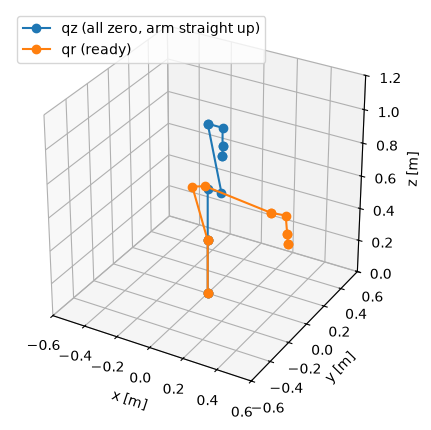

In [4]:
def plot_arm(ax, robot, q, **kw):
    # Draw the arm as a polyline through the origins of all link frames.
    pts = np.array([Tk.t for Tk in robot.fkine_all(q)])
    ax.plot(pts[:, 0], pts[:, 1], pts[:, 2], "o-", **kw)
    ax.set_xlim(-0.6, 0.6); ax.set_ylim(-0.6, 0.6); ax.set_zlim(0, 1.2)  # same scale on all axes
    ax.set_box_aspect((1, 1, 1))


fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(projection="3d")
plot_arm(ax, panda, panda.qz, label="qz (all zero, arm straight up)")
plot_arm(ax, panda, panda.qr, label="qr (ready)")
ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]"); ax.set_zlabel("z [m]")
ax.legend(loc="upper left")
plt.show()

### 1.3 Inverse kinematics

Inverse kinematics asks the opposite question: which $q$ gives the pose $T^*$? `ik_LM` solves it numerically with Levenberg-Marquardt. A redundant arm has infinitely many answers, so the solution depends on the start point `q0`. The cell solves the same target from five random starts.

In [5]:
T_goal = SE3.Trans(0.5, 0.2, 0.3) * SE3.OA([0, 1, 0], [0, 0, -1])  # gripper pointing down
rng = np.random.default_rng(0)
solutions = []
for k in range(5):
    q0 = rng.uniform(panda.qlim[0], panda.qlim[1])
    sol = panda.ik_LM(T_goal, q0=q0)  # an IKSolution with .q, .success, .iterations, .searches, .residual
    err = np.linalg.norm(panda.fkine(sol.q).t - T_goal.t)
    solutions.append(sol.q)
    print(f"start {k}: success={sol.success} searches={sol.searches} position error={err:.1e} m  q [deg]={np.degrees(sol.q).round(0)}")

start 0: success=True searches=5 position error=4.0e-04 m  q [deg]=[ 107.   29.  -93. -121.   33.  115. -137.]
start 1: success=True searches=2 position error=2.2e-06 m  q [deg]=[ -43.    0.   65. -123.   -0.  123. -113.]
start 2: success=True searches=1 position error=2.0e-04 m  q [deg]=[ 134.   -0. -112. -123.   -0.  123. -113.]
start 3: success=True searches=1 position error=3.6e-04 m  q [deg]=[ -67.    1.   89. -123.   -1.  123. -112.]
start 4: success=True searches=1 position error=1.0e-04 m  q [deg]=[ -42.    0.   63. -123.   -0.  123. -113.]


### 1.4 The Jacobian and manipulability

The Jacobian $J(q)$ maps joint velocities to the spatial velocity of the hand, $\nu = J(q)\,\dot q$, with $\nu = (v, \omega)$ in the world frame. For the Panda it is $6\times 7$. Yoshikawa's manipulability $m(q) = \sqrt{\det(J J^\top)}$ measures how well the arm can move in all directions. It is zero at a singularity, where some direction of hand motion is impossible.

In [6]:
J = panda.jacob0(panda.qr)
print("J shape:", J.shape, " rank:", np.linalg.matrix_rank(J))
print("singular values at qr:", np.linalg.svd(J, compute_uv=False))
print("singular values at qz:", np.linalg.svd(panda.jacob0(panda.qz), compute_uv=False))
print(f"manipulability qr = {panda.manipulability(panda.qr):.4f}, qz = {panda.manipulability(panda.qz):.1e}")
for k, qs in enumerate(solutions):
    print(f"IK solution {k}: manipulability = {panda.manipulability(qs):.4f}")

J shape: (6, 7)  rank: 6
singular values at qr: [1.8625 1.858  0.9394 0.3781 0.326  0.209 ]
singular values at qz: [2.0044 1.7565 0.4898 0.076  0.0671 0.    ]
manipulability qr = 0.0838, qz = 8.9e-35
IK solution 0: manipulability = 0.0508
IK solution 1: manipulability = 0.0342
IK solution 2: manipulability = 0.0302
IK solution 3: manipulability = 0.0026
IK solution 4: manipulability = 0.0365


### 1.5 Resolved-rate motion control, as your own loop

The toolbox offers `rtb.p_servo`, which returns a hand velocity $\nu^*$ that points from the current pose $T$ to the goal $T^*$ (a proportional controller on the pose error). With its default method `"rpy"` the velocity is expressed in the **hand frame**, so it must be paired with the hand-frame Jacobian $J_e$ (`jacobe`), not with the world-frame one (`jacob0`). Mixing the two frames makes the loop diverge, which is a good error to try once on purpose. The loop below inverts the Jacobian itself, so each step stays visible:

$$\dot q = J_e^{+}(q)\,\nu^*, \qquad q_{k+1} = q_k + \dot q\,\Delta t,$$

where $J_e^{+} = J_e^\top (J_e J_e^\top)^{-1}$ is the pseudo-inverse. For a redundant arm it gives the joint velocity with the smallest norm that produces $\nu^*$.

steps=413 final position error=5.6e-05 m


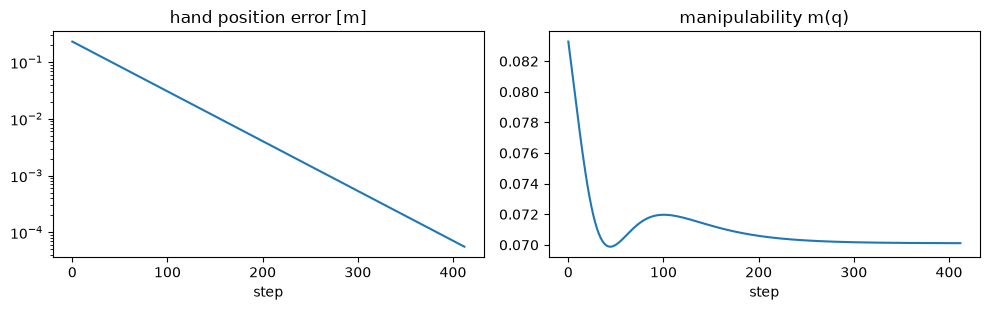

In [7]:
def resolved_rate(robot, q_start, T_goal, dt=0.01, gain=2.0, k_null=0.0, steps=1000):
    # Drive the hand to T_goal. k_null > 0 adds the null-space manipulability term of part 2.
    q = np.array(q_start, dtype=float)
    log = {"err": [], "m": [], "qd": []}
    for _ in range(steps):
        T = robot.fkine(q)
        v_star, arrived = rtb.p_servo(T, T_goal, gain=gain, threshold=0.001)
        J = robot.jacobe(q)  # hand frame, the same frame as v_star
        J_pinv = np.linalg.pinv(J)
        qd = J_pinv @ v_star
        if k_null:
            grad_m = robot.jacobm(q).ravel()  # gradient of m(q) with respect to q (checked against finite differences)
            qd += k_null * (np.eye(robot.n) - J_pinv @ J) @ grad_m
        q = q + qd * dt
        log["err"].append(np.linalg.norm(T_goal.t - T.t))
        log["m"].append(robot.manipulability(q))
        log["qd"].append(np.linalg.norm(qd))
        if arrived and not k_null:  # with a secondary goal, keep running so the self-motion can continue
            break
    return q, {k: np.array(v) for k, v in log.items()}


q_end, log = resolved_rate(panda, panda.qr, T_goal)
print(f"steps={len(log['err'])} final position error={log['err'][-1]:.1e} m")
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
axs[0].semilogy(log["err"]); axs[0].set_title("hand position error [m]"); axs[0].set_xlabel("step")
axs[1].plot(log["m"]); axs[1].set_title("manipulability m(q)"); axs[1].set_xlabel("step")
plt.tight_layout(); plt.show()

## 2. Make it yours: use the redundancy

The Panda has 7 joints for a 6-D task, so $J$ has a one-dimensional null space (the same for $J_0$ and $J_e$, because they differ only by a rotation of the velocity). A joint velocity in the null space moves the elbow but not the hand: this is the arm's **self-motion**. The projector $(I - J^{+}J)$ maps any wish onto that null space, so a secondary goal can be added without disturbing the primary one:

$$\dot q = J^{+}\nu^* + k\,(I - J^{+}J)\,\nabla_q m(q).$$

The secondary goal here is to climb the manipulability gradient $\nabla_q m$ (`jacobm`). The test starts at the IK solution of 1.3 with the lowest manipulability, which already holds the hand at the goal. So the primary task is only "stay where you are", and everything the arm does comes from the null-space term.

The run with `k_null = 0` stops after one step, because the hand is already at the goal and nothing else asks the arm to move. Change `k_null`, the start configuration, or the goal, and watch how the curves move. In the PhD context this is the same mechanism as the "whole-body" idea for Spot with its arm: the body and arm together have more joints than the gripper task needs, and the null space can serve a second objective, for example keeping a camera pointed at the drone.

start: IK solution with m = 0.0026


k_null = 0: steps=1, final m=0.0026, largest hand error=0.36 mm, joints inside limits: True
k_null = 5: steps=500, final m=0.0799, largest hand error=0.36 mm, joints inside limits: True
k_null = 20: steps=500, final m=0.1074, largest hand error=0.36 mm, joints inside limits: True


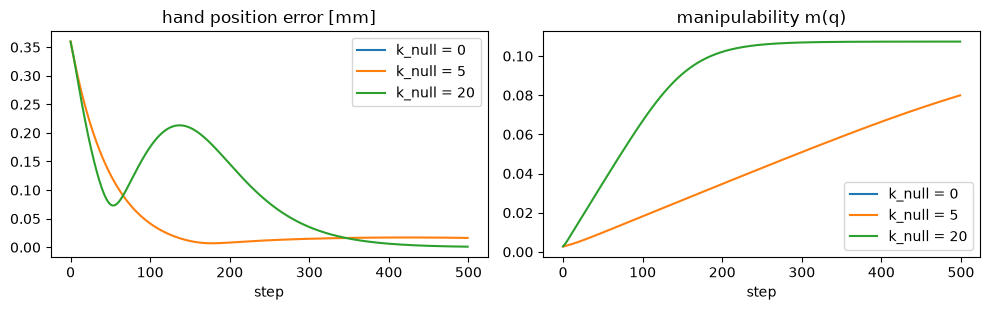

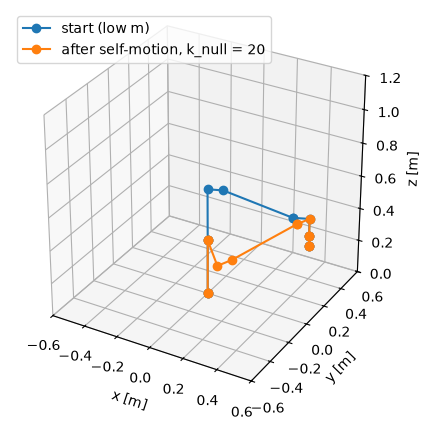

In [8]:
q_low = min(solutions, key=panda.manipulability)
print(f"start: IK solution with m = {panda.manipulability(q_low):.4f}")
runs = {k: resolved_rate(panda, q_low, T_goal, k_null=k, steps=500) for k in (0.0, 5.0, 20.0)}

fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
for k, (q_f, lg) in runs.items():
    lbl = f"k_null = {k:g}"
    axs[0].plot(1000 * lg["err"], label=lbl)
    axs[1].plot(lg["m"], label=lbl)
    inside = np.all((q_f >= panda.qlim[0]) & (q_f <= panda.qlim[1]))
    print(f"{lbl}: steps={len(lg['m'])}, final m={lg['m'][-1]:.4f}, largest hand error={1000 * lg['err'].max():.2f} mm, joints inside limits: {inside}")
axs[0].set_title("hand position error [mm]"); axs[1].set_title("manipulability m(q)")
for a in axs:
    a.set_xlabel("step"); a.legend()
plt.tight_layout(); plt.show()

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(projection="3d")
plot_arm(ax, panda, q_low, label="start (low m)")
plot_arm(ax, panda, runs[20.0][0], label="after self-motion, k_null = 20")
ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]"); ax.set_zlabel("z [m]")
ax.legend(loc="upper left")
plt.show()

A trap worth one try: start the same experiment from a configuration where joints 0, 2, 4 and 6 are zero (for example `panda.qz + np.radians([0, 5, 0, -10, 0, 10, 0])`). The arm then lies in one plane, the gradient of $m$ is orthogonal to the self-motion, and the null-space term does nothing at all. Print `(np.eye(7) - J_pinv @ J) @ panda.jacobm(q).ravel()` there to see the zero.

## 3. Questions for the reading group

1. The five IK solutions in 1.3 reach the same pose but have different manipulability. Which one would you send to the real arm, and why does the solver not choose it for you?
2. In 1.4 the Jacobian at `qz` loses rank. Which hand direction is lost there, and can you see it in the arm drawing of 1.2?
3. The pseudo-inverse gives the minimum-norm $\dot q$. What does that mean physically, and when is minimum norm the wrong choice?
4. In part 2 the hand error stays the same for every `k_null`, but $m$ changes a lot. Is that guaranteed? What happens when `k_null` is very large and the step `dt` stays the same?
5. Near a singularity the pseudo-inverse produces very large joint speeds. What would a damped least-squares inverse $J^\top(JJ^\top + \lambda^2 I)^{-1}$ change? Try it in `resolved_rate` with a start close to `qz`.
6. Joint limits are ignored by the loop. Print `panda.qlim` and check the final configurations. How would you add a second null-space objective that keeps the joints near the middle of their range?

## 4. Now read

Read in _Robotics, Vision and Control_ (3rd edition, Python), with the questions above in mind:

- "Representing Position and Orientation": the pose algebra behind 1.1.
- "Robot Arm Kinematics": forward kinematics, the ETS notation printed by the toolbox, and numerical inverse kinematics (1.2 and 1.3).
- "Manipulator Velocity": the Jacobian, singularities, manipulability, resolved-rate motion control and the null space (1.4, 1.5 and part 2).

The toolbox's own notebooks and the [ICRA 2021 paper on the toolbox](https://github.com/petercorke/robotics-toolbox-python) show the same ideas with the Swift 3-D browser simulator, which you can install with the `swift` extra when you want an animated view.